# Part 2 — Classification: Telco Customer Churn (PyTorch → ONNX → GitHub Pages)

**Goal:** predict whether a telecom customer will churn (cancel service) from their account, contract and service details.

**Pipeline:** read data → explore → clean / encode → stratified split 70/15/15 → train and compare 5 PyTorch classifiers → tune the decision threshold on validation → evaluate with F-measure, precision, recall, accuracy, ROC-AUC, MCC and the confusion matrix → export the best model to ONNX → verify → deploy with onnxruntime-web on GitHub Pages.

Conventions follow the class deployment example (ConstraintsMLprediction / Run10): scaling statistics live inside the model, Adam with lr = 0.001, ONNX export with `input1` / `output1` and opset 15.

In [1]:
## In Google Colab, torch / pandas / sklearn / matplotlib are preinstalled. Uncomment if needed:
## !pip install onnx onnxruntime mlxtend

In [2]:
import os, json, time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score, roc_auc_score,
                             matthews_corrcoef, confusion_matrix, classification_report, roc_curve)
import onnxruntime as rt

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()

np.set_printoptions(suppress=True)
torch.set_printoptions(sci_mode=False)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs('figures', exist_ok=True)
os.makedirs('ONNXmodels', exist_ok=True)
print('torch', torch.__version__, '| device:', device)

torch 2.14.1 | device: cpu


## 1. Read the data

In [3]:
URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(URL)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 2. Exploratory data analysis

In [5]:
print(df['Churn'].value_counts(), '\n')
print(df['Churn'].value_counts(normalize=True).round(4), '\n')

## TotalCharges is stored as text; 11 rows are blank spaces
tc_blank = df['TotalCharges'].astype(str).str.strip() == ''
print('Blank TotalCharges rows:', tc_blank.sum(), '| their tenure values:', df.loc[tc_blank, 'tenure'].unique())

for c in df.columns:
    if df[c].dtype != 'int64' and df[c].dtype != 'float64' and c not in ('customerID', 'TotalCharges'):
        print(f'{c:18s}', sorted(df[c].unique()))

Churn
No     5174
Yes    1869
Name: count, dtype: int64 

Churn
No    0.7346
Yes   0.2654
Name: proportion, dtype: float64 

Blank TotalCharges rows: 11 | their tenure values: [0]
gender             ['Female', 'Male']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              ['No', 'Yes']


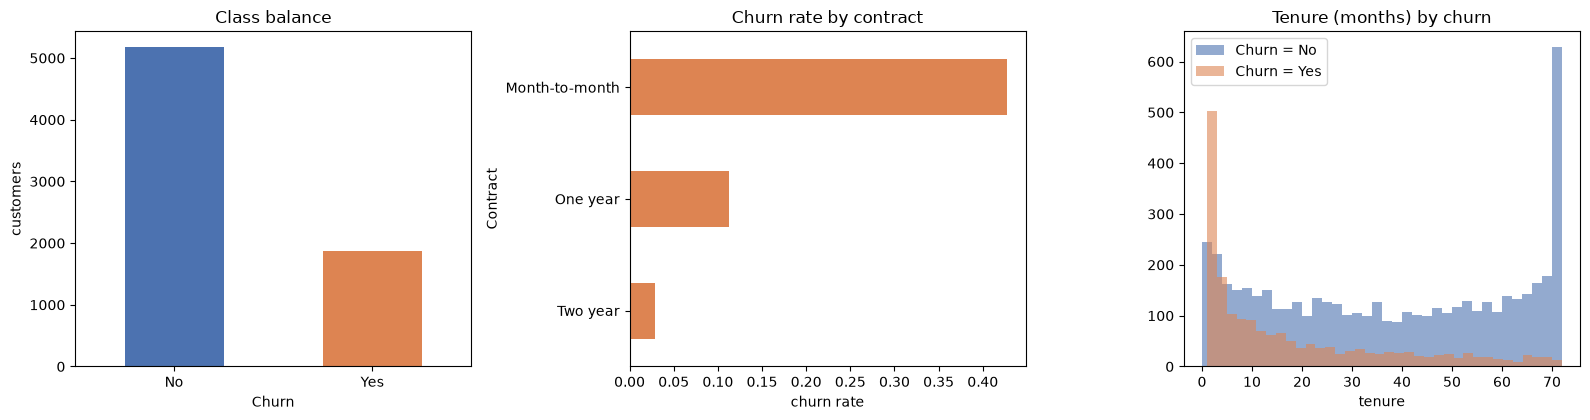

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
df['Churn'].value_counts().plot.bar(ax=axes[0], color=['#4C72B0', '#DD8452'])
axes[0].set_title('Class balance'); axes[0].set_ylabel('customers'); axes[0].tick_params(axis='x', rotation=0)

(df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean())
   .sort_values().plot.barh(ax=axes[1], color='#DD8452'))
axes[1].set_title('Churn rate by contract'); axes[1].set_xlabel('churn rate')

for label, color in [('No', '#4C72B0'), ('Yes', '#DD8452')]:
    axes[2].hist(df.loc[df.Churn == label, 'tenure'], bins=36, alpha=0.6, label=f'Churn = {label}', color=color)
axes[2].set_title('Tenure (months) by churn'); axes[2].set_xlabel('tenure'); axes[2].legend()
plt.tight_layout(); plt.savefig('figures/clf_eda.png', dpi=130); plt.show()

**Observations**
* The classes are imbalanced: about 26.5 % of customers churn. Accuracy alone would be misleading (predicting "No" for everyone gives 73 %), so the F-measure for the churn class is the main metric.
* Month-to-month contracts churn far more than one- or two-year contracts, and churn is concentrated in the first months of tenure.
* `TotalCharges` is text with 11 blanks — all of them brand-new customers with tenure 0.

## 3. Preprocessing

* Drop `customerID` (an identifier, not a feature).
* `TotalCharges` → numeric; the 11 blanks are customers with tenure 0, so they are set to 0.
* Yes/No columns → 1/0. "No internet service" / "No phone service" → 0 (the same information is already in `InternetService` / `PhoneService`).
* `gender` → `gender_Female` (1/0). `InternetService`, `Contract`, `PaymentMethod` → one-hot.
* Stratified split 70 / 15 / 15 so every set keeps the 26.5 % churn rate.
* `tenure`, `MonthlyCharges`, `TotalCharges` are standardized with training statistics stored inside the model; binary and one-hot columns stay 0/1.

In [7]:
INTERNET = ['DSL', 'Fiber optic', 'No']
CONTRACT = ['Month-to-month', 'One year', 'Two year']
PAYMENT  = ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
CONTINUOUS = ['tenure', 'MonthlyCharges', 'TotalCharges']
BINARY = ['SeniorCitizen', 'gender_Female', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
          'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
          'StreamingMovies', 'PaperlessBilling']
ONEHOT = (['InternetService_' + v for v in INTERNET] + ['Contract_' + v for v in CONTRACT]
          + ['PaymentMethod_' + v for v in PAYMENT])
INPUT_FEATURES = CONTINUOUS + BINARY + ONEHOT        ## 26 inputs (ONNX input order)
N_FEAT, N_CONT = len(INPUT_FEATURES), len(CONTINUOUS)

def preprocess(frame):
    d = pd.DataFrame(index=frame.index)
    d['tenure'] = frame['tenure'].astype(float)
    d['MonthlyCharges'] = frame['MonthlyCharges'].astype(float)
    d['TotalCharges'] = pd.to_numeric(frame['TotalCharges'].astype(str).str.strip().replace('', '0'))
    d['SeniorCitizen'] = frame['SeniorCitizen'].astype(float)
    d['gender_Female'] = (frame['gender'] == 'Female').astype(float)
    for c in ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
              'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']:
        d[c] = (frame[c] == 'Yes').astype(float)      ## 'No', 'No internet service', 'No phone service' -> 0
    for v in INTERNET: d['InternetService_' + v] = (frame['InternetService'] == v).astype(float)
    for v in CONTRACT: d['Contract_' + v]        = (frame['Contract'] == v).astype(float)
    for v in PAYMENT:  d['PaymentMethod_' + v]   = (frame['PaymentMethod'] == v).astype(float)
    return d[INPUT_FEATURES]

X_df = preprocess(df)
y_all = (df['Churn'] == 'Yes').astype(int).values
print(X_df.shape, '| any missing:', X_df.isna().any().any())
X_df.head()

(7043, 26) | any missing: False


,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,gender_Female,Partner,Dependents,PhoneService,MultipleLines,OnlineSecurity,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1.0000,29.8500,29.8500,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,...,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
1,34.0000,56.9500,"1,889.5000",0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,...,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000
2,2.0000,53.8500,108.1500,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,...,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
3,45.0000,42.3000,"1,840.7500",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,...,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000
4,2.0000,70.7000,151.6500,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,...,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000


### Correlation matrix of the encoded features and the target

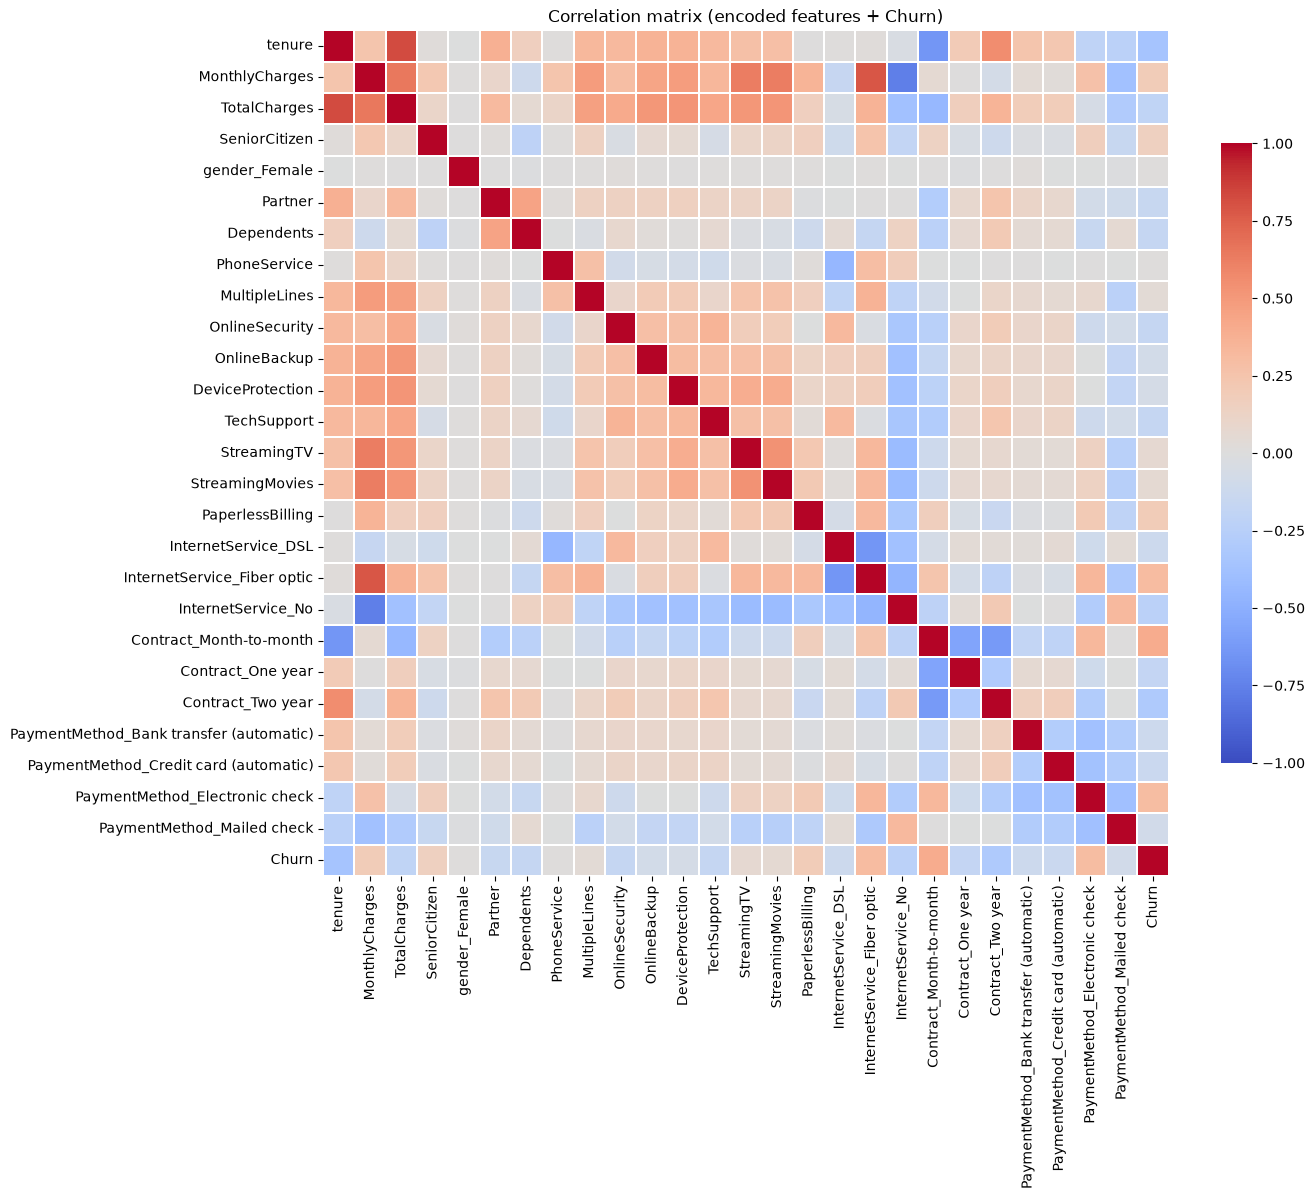

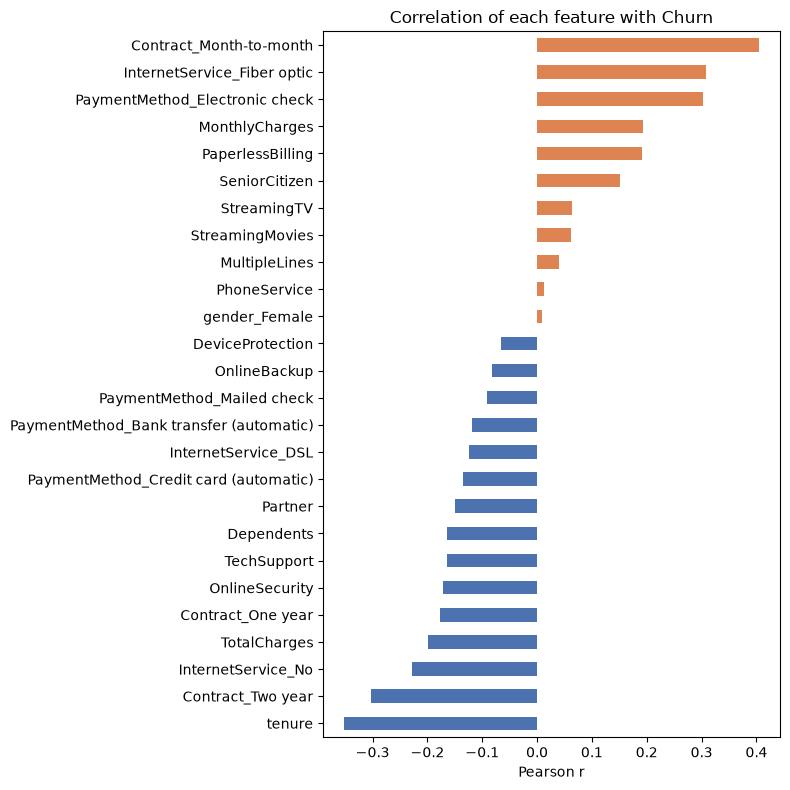

Contract_Month-to-month          0.4051
InternetService_Fiber optic      0.3080
PaymentMethod_Electronic check   0.3019
MonthlyCharges                   0.1934
PaperlessBilling                 0.1918
SeniorCitizen                    0.1509
StreamingTV                      0.0632
StreamingMovies                  0.0614
Name: Churn, dtype: float64

In [8]:
corr_df = X_df.assign(Churn=y_all).corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr_df, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, linewidths=0.3,
            cbar_kws={'shrink': 0.7})
plt.title('Correlation matrix (encoded features + Churn)')
plt.tight_layout(); plt.savefig('figures/clf_corr.png', dpi=130); plt.show()

churn_corr = corr_df['Churn'].drop('Churn').sort_values()
churn_corr.plot.barh(figsize=(8, 8), color=np.where(churn_corr > 0, '#DD8452', '#4C72B0'))
plt.title('Correlation of each feature with Churn'); plt.xlabel('Pearson r')
plt.tight_layout(); plt.savefig('figures/clf_corr_target.png', dpi=130); plt.show()
churn_corr.sort_values(ascending=False).head(8)

In [9]:
X = X_df.values.astype(np.float32)
row_ids = np.arange(len(X))           ## keep original row numbers so test rows can be traced back to df
X_train, X_tmp, y_train, y_tmp, id_train, id_tmp = train_test_split(
    X, y_all, row_ids, test_size=0.30, random_state=SEED, stratify=y_all)
X_val, X_test, y_val, y_test, id_val, id_test = train_test_split(
    X_tmp, y_tmp, id_tmp, test_size=0.50, random_state=SEED, stratify=y_tmp)
print('train', X_train.shape, f'churn {y_train.mean():.3f} | val', X_val.shape, f'churn {y_val.mean():.3f}',
      '| test', X_test.shape, f'churn {y_test.mean():.3f}')

X_train_tr, X_val_tr, X_test_tr = map(torch.tensor, (X_train, X_val, X_test))
y_train_tr = torch.tensor(y_train, dtype=torch.long)
y_val_tr   = torch.tensor(y_val,   dtype=torch.long)

epsilon = 0.0001
x_means      = X_train_tr.mean(0, keepdim=True)
x_deviations = X_train_tr.std(0, keepdim=True) + epsilon
x_means[:, N_CONT:] = 0.0          ## binary / one-hot columns stay 0/1
x_deviations[:, N_CONT:] = 1.0

## class weights for the imbalanced target ('balanced': n_samples / (n_classes * count))
counts = np.bincount(y_train)
class_weights = torch.tensor(len(y_train) / (2 * counts), dtype=torch.float32)
print('class weights (No, Yes):', class_weights.numpy())

BATCH_SIZE = 64
train_dl = DataLoader(TensorDataset(X_train_tr, y_train_tr), BATCH_SIZE, shuffle=True)

train (4930, 26) churn 0.265 | val (1056, 26) churn 0.265 | test (1057, 26) churn 0.266
class weights (No, Yes): [0.6805632 1.8845565]


## 4. Models (all PyTorch)

| # | Model | Idea |
|---|---|---|
| 1 | `LogisticRegressionNet` | single `nn.Linear` to 2 logits — logistic (softmax) regression |
| 2 | `MLP` | one hidden layer (64, ReLU) |
| 3 | `DeepNN` | three hidden layers (128 → 64 → 32, ReLU, dropout 0.2) |
| 4 | `F1plusF2` | class model: linear part F1 + nonlinear part F2 (sigmoid hidden layer, dropout 0.25) |
| 5 | `ResidualNet` | class model: two 64-unit ReLU layers with a projected skip connection |

All models output 2 logits and are trained with class-weighted cross-entropy, so missing a churner costs about 2.8× more than a false alarm.

In [10]:
class ScaledClassifier(nn.Module):
    def __init__(self, x_means, x_deviations):
        super().__init__()
        self.register_buffer('x_means', x_means.clone())
        self.register_buffer('x_deviations', x_deviations.clone())
    def core(self, z):
        raise NotImplementedError
    def forward(self, x):
        z = (x - self.x_means) / self.x_deviations
        return self.core(z)                       ## logits [N, 2]


class LogisticRegressionNet(ScaledClassifier):
    def __init__(self, *stats):
        super().__init__(*stats)
        self.linear1 = nn.Linear(N_FEAT, 2)
    def core(self, z):
        return self.linear1(z)


class MLP(ScaledClassifier):
    def __init__(self, *stats, hidden=64):
        super().__init__(*stats)
        self.net = nn.Sequential(nn.Linear(N_FEAT, hidden), nn.ReLU(), nn.Linear(hidden, 2))
    def core(self, z):
        return self.net(z)


class DeepNN(ScaledClassifier):
    def __init__(self, *stats, dropout_rate=0.2):
        super().__init__(*stats)
        self.net = nn.Sequential(
            nn.Linear(N_FEAT, 128), nn.ReLU(), nn.Dropout(dropout_rate),
            nn.Linear(128, 64),     nn.ReLU(), nn.Dropout(dropout_rate),
            nn.Linear(64, 32),      nn.ReLU(),
            nn.Linear(32, 2))
    def core(self, z):
        return self.net(z)


class F1plusF2(ScaledClassifier):
    def __init__(self, *stats, hidden=32):
        super().__init__(*stats)
        self.f1_linear1 = nn.Linear(N_FEAT, 2)
        self.f2_linear1 = nn.Linear(N_FEAT, hidden)
        self.f2_act1    = nn.Sigmoid()
        self.f2_dropout = nn.Dropout(0.25)
        self.f2_linear2 = nn.Linear(hidden, 2)
    def core(self, z):
        return self.f1_linear1(z) + self.f2_linear2(self.f2_dropout(self.f2_act1(self.f2_linear1(z))))


class ResidualNet(ScaledClassifier):
    def __init__(self, *stats, hidden=64, dropout_rate=0.1):
        super().__init__(*stats)
        self.fc1 = nn.Linear(N_FEAT, hidden); self.act1 = nn.ReLU(); self.dropout1 = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden, hidden); self.act2 = nn.ReLU(); self.dropout2 = nn.Dropout(dropout_rate)
        self.fc3 = nn.Linear(hidden, 2)
        self.input_proj = nn.Linear(N_FEAT, hidden)
    def core(self, z):
        x0 = self.input_proj(z)
        x1 = self.dropout1(self.act1(self.fc1(z)))
        x2 = self.dropout2(self.act2(self.fc2(x1)))
        return self.fc3(x2 + x0)

## 5. Training

Adam (lr = 0.001), class-weighted `CrossEntropyLoss`, mini-batches of 64, up to 300 epochs with early stopping (patience 25 on validation loss, best weights restored).

In [11]:
loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))

def train_model(model, train_dl, X_val_tr, y_val_tr, n_epochs=300, lr=0.001, patience=25, verbose_every=25):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    Xv, yv = X_val_tr.to(device), y_val_tr.to(device)
    history = {'train': [], 'val': []}
    best_val, best_state, bad_epochs = float('inf'), None, 0
    for epoch in range(n_epochs):
        model.train(); running = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward(); optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(train_dl.dataset)
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xv), yv).item()
        history['train'].append(train_loss); history['val'].append(val_loss)
        if val_loss < best_val - 1e-5:
            best_val, best_state, bad_epochs = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
        if epoch % verbose_every == 0:
            print(f'  epoch {epoch:3d} | train {train_loss:.4f} | val {val_loss:.4f}')
        if bad_epochs >= patience:
            print(f'  early stop at epoch {epoch}, best val loss {best_val:.4f}')
            break
    model.load_state_dict(best_state); model.eval()
    return model, history


def predict_proba(model, X_tr):
    model.eval()
    with torch.no_grad():
        return torch.softmax(model(X_tr.to(device)), dim=1)[:, 1].cpu().numpy()


def clf_metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {'accuracy':  accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred, zero_division=0),
            'recall':    recall_score(y_true, pred),
            'F1':        f1_score(y_true, pred),
            'macro_F1':  f1_score(y_true, pred, average='macro'),
            'MCC':       matthews_corrcoef(y_true, pred),
            'ROC_AUC':   roc_auc_score(y_true, prob)}


def best_threshold(y_true, prob):
    grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
    f1s = [f1_score(y_true, (prob >= t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(f1s))])

In [12]:
stats = (x_means, x_deviations)
model_builders = {
    'LogisticRegressionNet': lambda: LogisticRegressionNet(*stats),
    'MLP':                   lambda: MLP(*stats),
    'DeepNN':                lambda: DeepNN(*stats),
    'F1plusF2':              lambda: F1plusF2(*stats),
    'ResidualNet':           lambda: ResidualNet(*stats),
}

models, histories, rows, thresholds = {}, {}, [], {}
for name, build in model_builders.items():
    set_seed()
    print(f'=== {name} ===')
    t0 = time.time()
    model, hist = train_model(build(), train_dl, X_val_tr, y_val_tr)
    secs = time.time() - t0
    models[name], histories[name] = model, hist
    p_val, p_test = predict_proba(model, X_val_tr), predict_proba(model, X_test_tr)
    thr = best_threshold(y_val, p_val); thresholds[name] = thr
    m_val  = clf_metrics(y_val,  p_val,  thr)
    m_t05  = clf_metrics(y_test, p_test, 0.5)
    m_test = clf_metrics(y_test, p_test, thr)
    rows.append({'model': name, 'params': sum(p.numel() for p in model.parameters()),
                 'epochs': len(hist['val']), 'train_s': secs, 'threshold': thr,
                 'val_F1': m_val['F1'], 'val_ROC_AUC': m_val['ROC_AUC'], 'test_F1@0.5': m_t05['F1'], 'test_F1': m_test['F1'],
                 'test_precision': m_test['precision'], 'test_recall': m_test['recall'],
                 'test_accuracy': m_test['accuracy'], 'test_macro_F1': m_test['macro_F1'],
                 'test_MCC': m_test['MCC'], 'test_ROC_AUC': m_test['ROC_AUC']})
    print(f'  -> threshold {thr:.2f} | val F1 {m_val["F1"]:.4f} | test F1 {m_test["F1"]:.4f} | {secs:.0f}s\n')

=== LogisticRegressionNet ===


  epoch   0 | train 0.7040 | val 0.6318


  epoch  25 | train 0.4843 | val 0.4891


  epoch  50 | train 0.4837 | val 0.4887


  epoch  75 | train 0.4824 | val 0.4874


  early stop at epoch 94, best val loss 0.4869
  -> threshold 0.52 | val F1 0.6304 | test F1 0.6291 | 4s

=== MLP ===
  epoch   0 | train 0.5768 | val 0.5053


... (6 outputs left out)

  epoch  75 | train 0.4825 | val 0.4854


  early stop at epoch 93, best val loss 0.4850
  -> threshold 0.52 | val F1 0.6339 | test F1 0.6313 | 5s

=== ResidualNet ===
  epoch   0 | train 0.5267 | val 0.4998


  epoch  25 | train 0.4458 | val 0.5118


  early stop at epoch 31, best val loss 0.4888
  -> threshold 0.56 | val F1 0.6382 | test F1 0.6345 | 2s



## 6. Results and comparison

In [13]:
## rank by validation F1; ties broken by validation ROC-AUC
results = (pd.DataFrame(rows).sort_values(['val_F1', 'val_ROC_AUC'], ascending=False, kind='mergesort')
             .reset_index(drop=True))
results

,model,params,epochs,train_s,threshold,val_F1,val_ROC_AUC,test_F1@0.5,test_F1,test_precision,test_recall,test_accuracy,test_macro_F1,test_MCC,test_ROC_AUC
0,ResidualNet,7746,32,2.2961,0.5600,0.6382,0.8431,0.6232,0.6345,0.5635,0.7260,0.7777,0.7374,0.4863,0.8425
1,MLP,1858,33,1.1949,0.5300,0.6382,0.8453,0.6313,0.6338,0.5464,0.7544,0.7682,0.7321,0.4836,0.8460
2,DeepNN,13858,35,2.4883,0.5200,0.6348,0.8431,0.6339,0.6384,0.5423,0.7758,0.7663,0.7329,0.4902,0.8457
3,F1plusF2,984,94,4.5192,0.5200,0.6339,0.8456,0.6291,0.6313,0.5390,0.7616,0.7635,0.7286,0.4796,0.8448
4,LogisticRegressionNet,54,95,3.8339,0.5200,0.6304,0.8443,0.6291,0.6291,0.5394,0.7544,0.7635,0.7277,0.4764,0.8436


In [14]:
BEST_NAME  = results.loc[0, 'model']          ## chosen on VALIDATION F1 (tie-break: val ROC-AUC), reported on TEST
best_model = models[BEST_NAME]
BEST_THRESHOLD = thresholds[BEST_NAME]
p_test_best = predict_proba(best_model, X_test_tr)
y_pred_best = (p_test_best >= BEST_THRESHOLD).astype(int)
print(f'Best model (by validation F1): {BEST_NAME}  | decision threshold = {BEST_THRESHOLD:.2f}\n')
print(classification_report(y_test, y_pred_best, target_names=['No churn', 'Churn'], digits=4))

Best model (by validation F1): ResidualNet  | decision threshold = 0.56

              precision    recall  f1-score   support

    No churn     0.8892    0.7964    0.8402       776
       Churn     0.5635    0.7260    0.6345       281

    accuracy                         0.7777      1057
   macro avg     0.7264    0.7612    0.7374      1057
weighted avg     0.8026    0.7777    0.7856      1057



In [15]:
## Reference point only (not PyTorch): scikit-learn baselines on the same split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
Xs_tr = ((X_train_tr - x_means) / x_deviations).numpy(); Xs_te = ((X_test_tr - x_means) / x_deviations).numpy()
refs = {}
for nm, est in [('Always "No churn"', DummyClassifier(strategy='most_frequent')),
                ('sklearn LogisticRegression (balanced)', LogisticRegression(max_iter=2000, class_weight='balanced')),
                ('HistGradientBoosting (balanced)', HistGradientBoostingClassifier(random_state=SEED, class_weight='balanced'))]:
    est.fit(Xs_tr, y_train); pred = est.predict(Xs_te)
    refs[nm] = {'accuracy': accuracy_score(y_test, pred), 'F1': f1_score(y_test, pred)}
pd.DataFrame(refs).T

,accuracy,F1
"Always ""No churn""",0.7342,0.0000
sklearn LogisticRegression (balanced),0.7474,0.6213
HistGradientBoosting (balanced),0.7569,0.6100


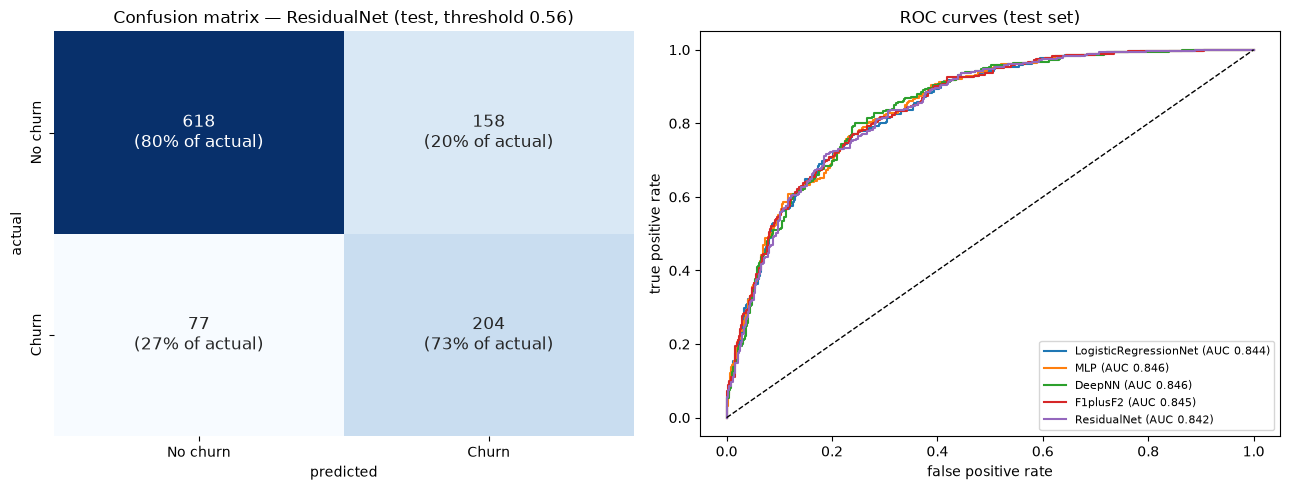

TN, FP, FN, TP = [618 158  77 204]


In [16]:
cm = confusion_matrix(y_test, y_pred_best)
cm_row = cm / cm.sum(axis=1, keepdims=True)
cell_text = np.array([[f'{cm[i, j]}\n({cm_row[i, j]:.0%} of actual)' for j in range(2)] for i in range(2)])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=cell_text, fmt='', cmap='Blues', cbar=False, ax=axes[0], annot_kws={'size': 12},
            xticklabels=['No churn', 'Churn'], yticklabels=['No churn', 'Churn'])
axes[0].set_xlabel('predicted'); axes[0].set_ylabel('actual')
axes[0].set_title(f'Confusion matrix — {BEST_NAME} (test, threshold {BEST_THRESHOLD:.2f})')

for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, predict_proba(model, X_test_tr))
    axes[1].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y_test, predict_proba(model, X_test_tr)):.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel('false positive rate'); axes[1].set_ylabel('true positive rate')
axes[1].set_title('ROC curves (test set)'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/clf_confusion_roc.png', dpi=130); plt.show()
print('TN, FP, FN, TP =', cm.ravel())

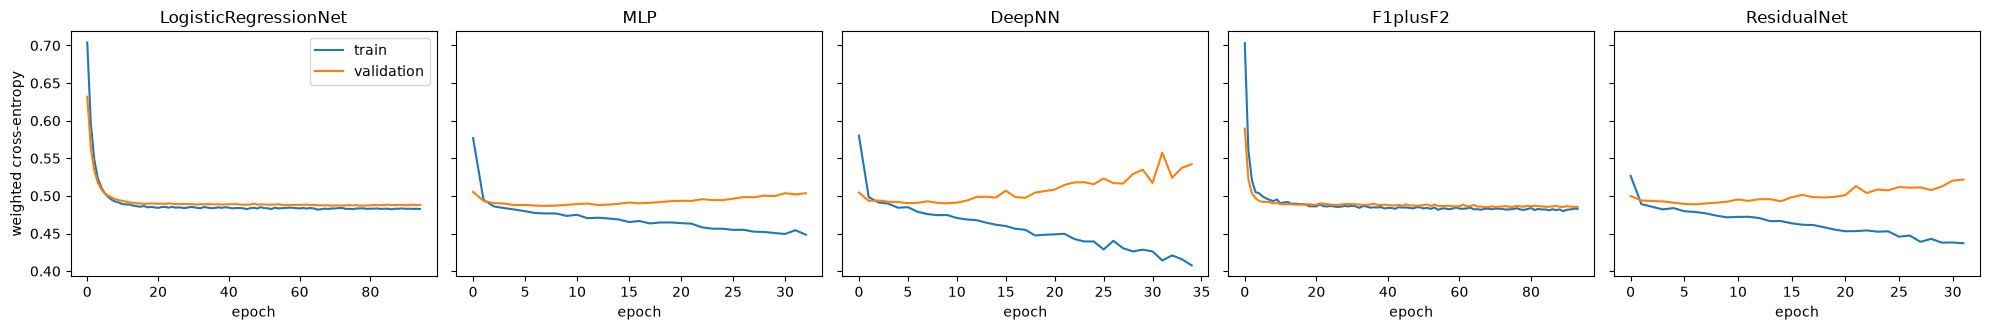

In [17]:
fig, axes = plt.subplots(1, len(histories), figsize=(4 * len(histories), 3.4), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h['train'], label='train'); ax.plot(h['val'], label='validation')
    ax.set_title(name); ax.set_xlabel('epoch')
axes[0].set_ylabel('weighted cross-entropy'); axes[0].legend()
plt.tight_layout(); plt.savefig('figures/clf_learning_curves.png', dpi=130); plt.show()

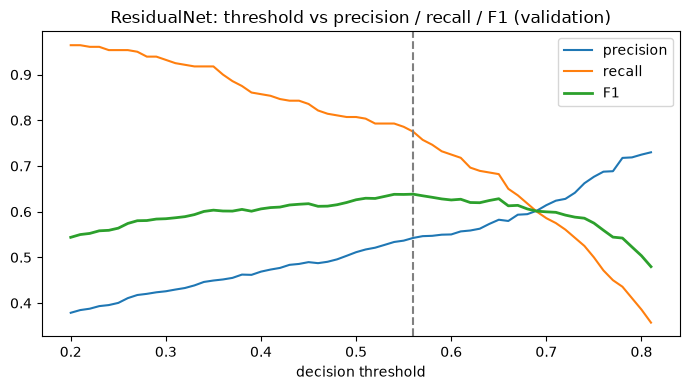

In [18]:
## Threshold trade-off for the best model on the validation set
p_val_best = predict_proba(best_model, X_val_tr)
grid = np.arange(0.2, 0.81, 0.01)
prec = [precision_score(y_val, (p_val_best >= t).astype(int), zero_division=0) for t in grid]
rec  = [recall_score(y_val, (p_val_best >= t).astype(int)) for t in grid]
f1s  = [f1_score(y_val, (p_val_best >= t).astype(int)) for t in grid]
plt.figure(figsize=(7, 4))
plt.plot(grid, prec, label='precision'); plt.plot(grid, rec, label='recall'); plt.plot(grid, f1s, label='F1', lw=2)
plt.axvline(BEST_THRESHOLD, color='gray', ls='--'); plt.xlabel('decision threshold'); plt.legend()
plt.title(f'{BEST_NAME}: threshold vs precision / recall / F1 (validation)')
plt.tight_layout(); plt.savefig('figures/clf_threshold.png', dpi=130); plt.show()

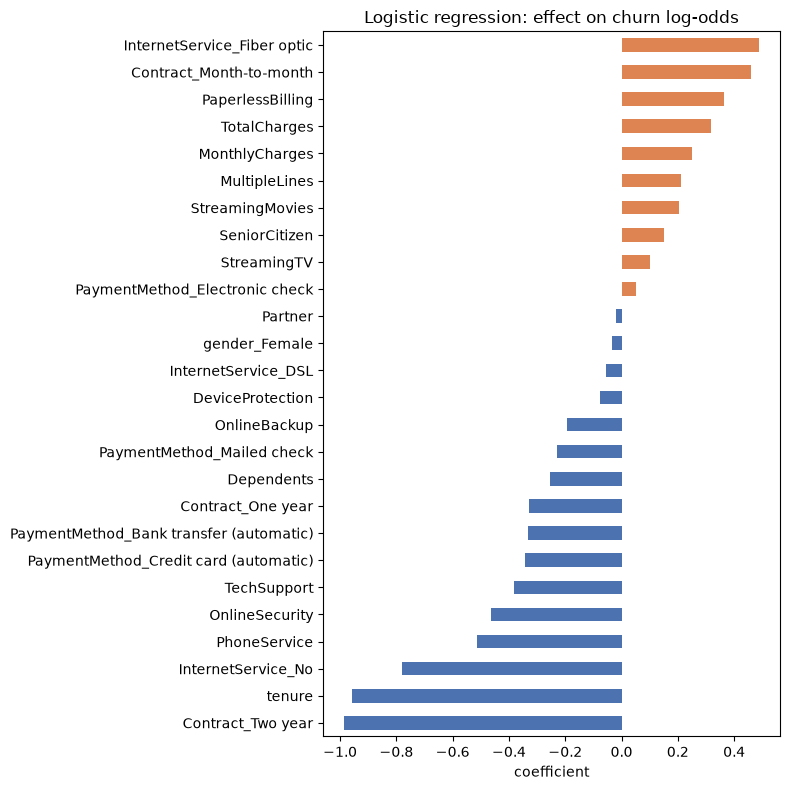

In [19]:
## Interpretability: coefficients of the logistic-regression model (standardized inputs, churn logit minus no-churn logit)
lr_model = models['LogisticRegressionNet']
w = (lr_model.linear1.weight[1] - lr_model.linear1.weight[0]).detach().cpu().numpy()
coef = pd.Series(w, index=INPUT_FEATURES).sort_values()
coef.plot.barh(figsize=(8, 8), color=np.where(coef > 0, '#DD8452', '#4C72B0'))
plt.title('Logistic regression: effect on churn log-odds'); plt.xlabel('coefficient')
plt.tight_layout(); plt.savefig('figures/clf_lr_coefficients.png', dpi=130); plt.show()

## 7. Export the best model to ONNX

The export wrapper applies softmax, so `output1` is `[P(no churn), P(churn)]`. The web page compares `P(churn)` with the tuned threshold.

In [20]:
class ExportWrapper(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return torch.softmax(self.m(x), dim=1)

export_model = ExportWrapper(copy.deepcopy(best_model).to('cpu')).eval().float()
dummy_input = torch.rand(1, N_FEAT, dtype=torch.float32)
ONNX_PATH = 'ONNXmodels/churn_classifier.onnx'

torch.onnx.export(
    export_model,
    dummy_input,
    ONNX_PATH,
    input_names=['input1'],
    output_names=['output1'],
    opset_version=15,
    do_constant_folding=True,
    dynamic_axes={'input1': {0: 'batch'}, 'output1': {0: 'batch'}},
    dynamo=False,
)
print('ONNX model saved:', ONNX_PATH, f'({os.path.getsize(ONNX_PATH)/1024:.1f} KB)')

/tmp/ipykernel_291/3691635447.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX model saved: ONNXmodels/churn_classifier.onnx (31.8 KB)


In [21]:
sess = rt.InferenceSession(ONNX_PATH)
print('inputs :', [(i.name, i.shape) for i in sess.get_inputs()])
print('outputs:', [(o.name, o.shape) for o in sess.get_outputs()])
onnx_prob = sess.run(['output1'], {'input1': X_test.astype(np.float32)})[0][:, 1]
print('max |ONNX - PyTorch| probability difference =', np.abs(onnx_prob - p_test_best).max())
print('ONNX test F1 =', f1_score(y_test, (onnx_prob >= BEST_THRESHOLD).astype(int)))

inputs : [('input1', ['batch', 26])]
outputs: [('output1', ['batch', 2])]
max |ONNX - PyTorch| probability difference = 5.9604645e-08
ONNX test F1 = 0.6345256609642301


In [22]:
samples = []
for i in np.r_[np.where(y_test == 1)[0][:2], np.where(y_test == 0)[0][:1]]:
    row = df.drop(columns=['customerID', 'Churn']).iloc[id_test[i]].to_dict()
    samples.append({'raw': {k: (v.item() if hasattr(v, 'item') else v) for k, v in row.items()},
                    'encoded': X_test[i].tolist(), 'actual': int(y_test[i]), 'onnx_prob': float(onnx_prob[i])})
    print('actual', y_test[i], '| P(churn) =', round(float(onnx_prob[i]), 4))

summary = {'best_model': BEST_NAME, 'threshold': BEST_THRESHOLD, 'input_features': INPUT_FEATURES,
           'results': results.to_dict(orient='records'), 'references': refs,
           'confusion_matrix': cm.tolist(), 'samples': samples,
           'top_churn_correlations': churn_corr.sort_values(ascending=False).head(6).to_dict(),
           'lowest_churn_correlations': churn_corr.sort_values().head(6).to_dict()}
with open('ONNXmodels/classification_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=float)
print('saved ONNXmodels/classification_summary.json')

actual 1 | P(churn) = 0.6805
actual 1 | P(churn) = 0.8788
actual 0 | P(churn) = 0.2212
saved ONNXmodels/classification_summary.json
